In [1]:

# STEP 1: Install required libraries

!pip install -q fairlearn

print("Libraries installed successfully!")


Libraries installed successfully!


In [2]:

# STEP 2: Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

from fairlearn.metrics import (
    MetricFrame,
    selection_rate,
    true_positive_rate,
    false_positive_rate,
    demographic_parity_difference,
    demographic_parity_ratio,
    equalized_odds_difference
)

from fairlearn.postprocessing import ThresholdOptimizer

print("All imports completed successfully!")


All imports completed successfully!


In [3]:

# STEP 3: Upload Adult Census Income Dataset

from google.colab import files

uploaded = files.upload()

print("Dataset uploaded successfully!")


Saving adult.csv.zip to adult.csv.zip
Dataset uploaded successfully!


In [7]:

# STEP 4: Extract and Load the ZIP Dataset

import zipfile
import io
import pandas as pd

# Get uploaded ZIP filename
filename = list(uploaded.keys())[0]

print("Uploaded file:", filename)

# Extract ZIP and identify CSV file
with zipfile.ZipFile(io.BytesIO(uploaded[filename]), 'r') as zip_ref:

    csv_files = [
        f for f in zip_ref.namelist()
        if f.lower().endswith('.csv') and not f.startswith('__MACOSX/')
    ]

    print("CSV files found:", csv_files)

    if not csv_files:
        raise FileNotFoundError("No CSV file found inside ZIP!")

    # Read the first CSV file
    with zip_ref.open(csv_files[0]) as file:
        df = pd.read_csv(file, skipinitialspace=True)

print("\nDataset loaded successfully!")

print("\nDataset Shape:", df.shape)

print("\nFirst 5 Records:")
display(df.head())

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())


Uploaded file: adult.csv.zip
CSV files found: ['adult.csv']

Dataset loaded successfully!

Dataset Shape: (32561, 15)

First 5 Records:


,age,workclass,fnlwgt,education,education.num,marital.status,occupation,relationship,race,sex,capital.gain,capital.loss,hours.per.week,native.country,income
0,90,?,77053,HS-grad,9,Widowed,?,Not-in-family,White,Female,0,4356,40,United-States,<=50K
1,82,Private,132870,HS-grad,9,Widowed,Exec-managerial,Not-in-family,White,Female,0,4356,18,United-States,<=50K
2,66,?,186061,Some-college,10,Widowed,?,Unmarried,Black,Female,0,4356,40,United-States,<=50K
3,54,Private,140359,7th-8th,4,Divorced,Machine-op-inspct,Unmarried,White,Female,0,3900,40,United-States,<=50K
4,41,Private,264663,Some-college,10,Separated,Prof-specialty,Own-child,White,Female,0,3900,40,United-States,<=50K



Column Names:
['age', 'workclass', 'fnlwgt', 'education', 'education.num', 'marital.status', 'occupation', 'relationship', 'race', 'sex', 'capital.gain', 'capital.loss', 'hours.per.week', 'native.country', 'income']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32561 entries, 0 to 32560
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   age             32561 non-null  int64 
 1   workclass       32561 non-null  object
 2   fnlwgt          32561 non-null  int64 
 3   education       32561 non-null  object
 4   education.num   32561 non-null  int64 
 5   marital.status  32561 non-null  object
 6   occupation      32561 non-null  object
 7   relationship    32561 non-null  object
 8   race            32561 non-null  object
 9   sex             32561 non-null  object
 10  capital.gain    32561 non-null  int64 
 11  capital.loss    32561 non-null  int64 
 12  hours.per.week  32561 non-null 

In [8]:

# STEP 6: Data Cleaning

# Remove leading and trailing spaces from column names
df.columns = df.columns.str.strip()

# Remove whitespace from string values
for col in df.select_dtypes(include='object').columns:
    df[col] = df[col].str.strip()

# Replace '?' with NaN
df.replace('?', np.nan, inplace=True)

# Remove rows containing missing values
df.dropna(inplace=True)

# Remove duplicate records
df.drop_duplicates(inplace=True)

# Normalize income labels
df['income'] = df['income'].str.replace('.', '', regex=False).str.strip()

# Convert target variable into binary format
df['income'] = df['income'].map({
    '<=50K': 0,
    '>50K': 1
})

# Remove any rows with invalid target labels
df.dropna(subset=['income'], inplace=True)
df['income'] = df['income'].astype(int)

print("Data cleaning completed!")
print("\nCleaned Dataset Shape:", df.shape)

print("\nIncome Distribution:")
print(df['income'].value_counts())

print("\nSex Distribution:")
print(df['sex'].value_counts())

print("\nRemaining Missing Values:", df.isnull().sum().sum())


Data cleaning completed!

Cleaned Dataset Shape: (30139, 15)

Income Distribution:
income
0    22633
1     7506
Name: count, dtype: int64

Sex Distribution:
sex
Male      20366
Female     9773
Name: count, dtype: int64

Remaining Missing Values: 0


In [9]:

# STEP 7: Separate Features and Target

# Sensitive attribute (used ONLY for fairness analysis)
sensitive_features = df['sex'].copy()

# Target variable
y = df['income'].copy()

# Model features (exclude income and sex)
X = df.drop(columns=['income', 'sex'])

print("Features Shape:", X.shape)
print("Target Shape:", y.shape)
print("Sensitive Attribute Shape:", sensitive_features.shape)

print("\nSensitive Attribute:")
print(sensitive_features.value_counts())

print("\nTarget Classes:")
print(y.value_counts())


Features Shape: (30139, 13)
Target Shape: (30139,)
Sensitive Attribute Shape: (30139,)

Sensitive Attribute:
sex
Male      20366
Female     9773
Name: count, dtype: int64

Target Classes:
income
0    22633
1     7506
Name: count, dtype: int64


In [10]:

# STEP 8: Identify Feature Types

numeric_features = X.select_dtypes(
    include=['int64', 'float64']
).columns.tolist()

categorical_features = X.select_dtypes(
    include=['object', 'category']
).columns.tolist()

print("Numerical Features:")
print(numeric_features)

print("\nCategorical Features:")
print(categorical_features)


Numerical Features:
['age', 'fnlwgt', 'education.num', 'capital.gain', 'capital.loss', 'hours.per.week']

Categorical Features:
['workclass', 'education', 'marital.status', 'occupation', 'relationship', 'race', 'native.country']


In [11]:

# STEP 9: Preprocessing and Train-Test Split

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split

# Create preprocessing pipeline
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numeric_features),
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features)
    ]
)

# Split data
X_train, X_test, y_train, y_test, A_train, A_test = train_test_split(
    X,
    y,
    sensitive_features,
    test_size=0.30,
    random_state=42,
    stratify=y
)

print("Data splitting completed!")

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

print("\nTraining shape:", X_train.shape)
print("Testing shape:", X_test.shape)

print("\nTraining income distribution:")
print(y_train.value_counts(normalize=True))

print("\nTesting income distribution:")
print(y_test.value_counts(normalize=True))


Data splitting completed!
Training samples: 21097
Testing samples: 9042

Training shape: (21097, 13)
Testing shape: (9042, 13)

Training income distribution:
income
0    0.75096
1    0.24904
Name: proportion, dtype: float64

Testing income distribution:
income
0    0.75094
1    0.24906
Name: proportion, dtype: float64


In [12]:

# STEP 10: Train Logistic Regression Model

from sklearn.linear_model import LogisticRegression

# Create complete machine learning pipeline
baseline_model = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(max_iter=1000))
])

# Train model
baseline_model.fit(X_train, y_train)

# Make predictions
y_pred_baseline = baseline_model.predict(X_test)

# Calculate accuracy
baseline_accuracy = accuracy_score(y_test, y_pred_baseline)

print("Baseline Logistic Regression Model")
print("-----------------------------------")
print("Accuracy:", round(baseline_accuracy, 4))
print("Model trained successfully!")


Baseline Logistic Regression Model
-----------------------------------
Accuracy: 0.8524
Model trained successfully!


In [13]:

# STEP 11: Baseline Fairness Audit

metrics = {
    'Accuracy': accuracy_score,
    'Selection Rate': selection_rate,
    'TPR': true_positive_rate,
    'FPR': false_positive_rate
}

baseline_metric_frame = MetricFrame(
    metrics=metrics,
    y_true=y_test,
    y_pred=y_pred_baseline,
    sensitive_features=A_test
)

print("BASELINE FAIRNESS METRICS")
print("=========================")

display(baseline_metric_frame.by_group)

print("\nOverall Metrics:")
display(baseline_metric_frame.overall)


BASELINE FAIRNESS METRICS


,Accuracy,Selection Rate,TPR,FPR
sex,,,,
Female,0.923943,0.083220,0.531915,0.026508
Male,0.818003,0.259083,0.622465,0.092190



Overall Metrics:


,0
Accuracy,0.852356
Selection Rate,0.202057
TPR,0.609236
FPR,0.067010


In [14]:

# STEP 12: Calculate Fairness Metrics

baseline_dp_diff = demographic_parity_difference(
    y_test,
    y_pred_baseline,
    sensitive_features=A_test
)

baseline_dp_ratio = demographic_parity_ratio(
    y_test,
    y_pred_baseline,
    sensitive_features=A_test
)

baseline_eo_diff = equalized_odds_difference(
    y_test,
    y_pred_baseline,
    sensitive_features=A_test
)

print("BASELINE FAIRNESS RESULTS")
print("=========================")

print("Overall Accuracy:", round(baseline_accuracy, 4))

print("Demographic Parity Difference:",
      round(baseline_dp_diff, 4))

print("Demographic Parity Ratio:",
      round(baseline_dp_ratio, 4))

print("Equalized Odds Difference:",
      round(baseline_eo_diff, 4))

print("\nFour-Fifths Rule:",
      "PASS" if baseline_dp_ratio >= 0.80 else "FAIL - Potential Bias")


BASELINE FAIRNESS RESULTS
Overall Accuracy: 0.8524
Demographic Parity Difference: 0.1759
Demographic Parity Ratio: 0.3212
Equalized Odds Difference: 0.0906

Four-Fifths Rule: FAIL - Potential Bias


In [15]:

# STEP 13: ThresholdOptimizer - Demographic Parity

from fairlearn.postprocessing import ThresholdOptimizer

dp_optimizer = ThresholdOptimizer(
    estimator=baseline_model,
    constraints='demographic_parity',
    objective='accuracy_score',
    predict_method='predict_proba',
    prefit=True
)

# Fit fairness postprocessor
dp_optimizer.fit(
    X_train,
    y_train,
    sensitive_features=A_train
)

# Generate mitigated predictions
y_pred_dp = dp_optimizer.predict(
    X_test,
    sensitive_features=A_test,
    random_state=42
)

dp_accuracy = accuracy_score(y_test, y_pred_dp)

print("DEMOGRAPHIC PARITY MITIGATION")
print("============================")
print("Accuracy:", round(dp_accuracy, 4))
print("Mitigation completed successfully!")


DEMOGRAPHIC PARITY MITIGATION
Accuracy: 0.8322
Mitigation completed successfully!


In [16]:

# STEP 14: Evaluate Demographic Parity Model

dp_metric_frame = MetricFrame(
    metrics=metrics,
    y_true=y_test,
    y_pred=y_pred_dp,
    sensitive_features=A_test
)

dp_diff = demographic_parity_difference(
    y_test, y_pred_dp, sensitive_features=A_test
)

dp_ratio = demographic_parity_ratio(
    y_test, y_pred_dp, sensitive_features=A_test
)

dp_eo_diff = equalized_odds_difference(
    y_test, y_pred_dp, sensitive_features=A_test
)

print("DEMOGRAPHIC PARITY FAIRNESS METRICS")
print("===================================")

display(dp_metric_frame.by_group)

print("\nDemographic Parity Difference:", round(dp_diff, 4))
print("Demographic Parity Ratio:", round(dp_ratio, 4))
print("Equalized Odds Difference:", round(dp_eo_diff, 4))


DEMOGRAPHIC PARITY FAIRNESS METRICS


,Accuracy,Selection Rate,TPR,FPR
sex,,,,
Female,0.898363,0.162005,0.768997,0.085286
Male,0.800491,0.173159,0.458138,0.042274



Demographic Parity Difference: 0.0112
Demographic Parity Ratio: 0.9356
Equalized Odds Difference: 0.3109


In [17]:

# STEP 15: ThresholdOptimizer - Equalized Odds

eo_optimizer = ThresholdOptimizer(
    estimator=baseline_model,
    constraints='equalized_odds',
    objective='accuracy_score',
    predict_method='predict_proba',
    prefit=True
)

# Fit fairness postprocessor
eo_optimizer.fit(
    X_train,
    y_train,
    sensitive_features=A_train
)

# Generate mitigated predictions
y_pred_eo = eo_optimizer.predict(
    X_test,
    sensitive_features=A_test,
    random_state=42
)

eo_accuracy = accuracy_score(y_test, y_pred_eo)

print("EQUALIZED ODDS MITIGATION")
print("=========================")
print("Accuracy:", round(eo_accuracy, 4))
print("Mitigation completed successfully!")


EQUALIZED ODDS MITIGATION
Accuracy: 0.8371
Mitigation completed successfully!


In [18]:

# STEP 16: Evaluate Equalized Odds Model

eo_metric_frame = MetricFrame(
    metrics=metrics,
    y_true=y_test,
    y_pred=y_pred_eo,
    sensitive_features=A_test
)

eo_dp_diff = demographic_parity_difference(
    y_test, y_pred_eo, sensitive_features=A_test
)

eo_dp_ratio = demographic_parity_ratio(
    y_test, y_pred_eo, sensitive_features=A_test
)

eo_diff = equalized_odds_difference(
    y_test, y_pred_eo, sensitive_features=A_test
)

print("EQUALIZED ODDS FAIRNESS METRICS")
print("===============================")

display(eo_metric_frame.by_group)

print("\nDemographic Parity Difference:", round(eo_dp_diff, 4))
print("Demographic Parity Ratio:", round(eo_dp_ratio, 4))
print("Equalized Odds Difference:", round(eo_diff, 4))


EQUALIZED ODDS FAIRNESS METRICS


,Accuracy,Selection Rate,TPR,FPR
sex,,,,
Female,0.893929,0.103683,0.489362,0.054937
Male,0.809820,0.207365,0.527301,0.060425



Demographic Parity Difference: 0.1037
Demographic Parity Ratio: 0.5
Equalized Odds Difference: 0.0379


In [19]:

# STEP 17: Model Comparison Table

def get_selection_rates(metric_frame):
    group_rates = metric_frame.by_group['Selection Rate']
    return group_rates['Male'], group_rates['Female']


base_m, base_f = get_selection_rates(baseline_metric_frame)
dp_m, dp_f = get_selection_rates(dp_metric_frame)
eo_m, eo_f = get_selection_rates(eo_metric_frame)

comparison = pd.DataFrame({
    'Model': [
        'Baseline',
        'TO: Demographic Parity',
        'TO: Equalized Odds'
    ],
    'Accuracy': [
        baseline_accuracy,
        dp_accuracy,
        eo_accuracy
    ],
    'Selection Rate Male': [
        base_m, dp_m, eo_m
    ],
    'Selection Rate Female': [
        base_f, dp_f, eo_f
    ],
    'DP Difference': [
        baseline_dp_diff, dp_diff, eo_dp_diff
    ],
    'DP Ratio': [
        baseline_dp_ratio, dp_ratio, eo_dp_ratio
    ],
    'EO Difference': [
        baseline_eo_diff, dp_eo_diff, eo_diff
    ]
})

print("FINAL MODEL COMPARISON")
print("======================")

display(comparison.round(4))


FINAL MODEL COMPARISON


,Model,Accuracy,Selection Rate Male,Selection Rate Female,DP Difference,DP Ratio,EO Difference
0,Baseline,0.8524,0.2591,0.0832,0.1759,0.3212,0.0906
1,TO: Demographic Parity,0.8322,0.1732,0.1620,0.0112,0.9356,0.3109
2,TO: Equalized Odds,0.8371,0.2074,0.1037,0.1037,0.5000,0.0379


In [20]:

# STEP 18: Calculate Accuracy Loss

accuracy_loss_dp = baseline_accuracy - dp_accuracy
accuracy_loss_eo = baseline_accuracy - eo_accuracy

print("ACCURACY VS FAIRNESS ANALYSIS")
print("=============================")

print("Baseline Accuracy:", round(baseline_accuracy, 4))

print("\nDemographic Parity:")
print("Accuracy:", round(dp_accuracy, 4))
print("Accuracy Loss:", round(accuracy_loss_dp, 4))

print("\nEqualized Odds:")
print("Accuracy:", round(eo_accuracy, 4))
print("Accuracy Loss:", round(accuracy_loss_eo, 4))

if accuracy_loss_dp >= 0:
    print("\nDP Accuracy Loss (%):",
          round(accuracy_loss_dp * 100, 2))
else:
    print("\nDP Accuracy Improvement (%):",
          round(abs(accuracy_loss_dp) * 100, 2))

if accuracy_loss_eo >= 0:
    print("EO Accuracy Loss (%):",
          round(accuracy_loss_eo * 100, 2))
else:
    print("EO Accuracy Improvement (%):",
          round(abs(accuracy_loss_eo) * 100, 2))


ACCURACY VS FAIRNESS ANALYSIS
Baseline Accuracy: 0.8524

Demographic Parity:
Accuracy: 0.8322
Accuracy Loss: 0.0201

Equalized Odds:
Accuracy: 0.8371
Accuracy Loss: 0.0153

DP Accuracy Loss (%): 2.01
EO Accuracy Loss (%): 1.53


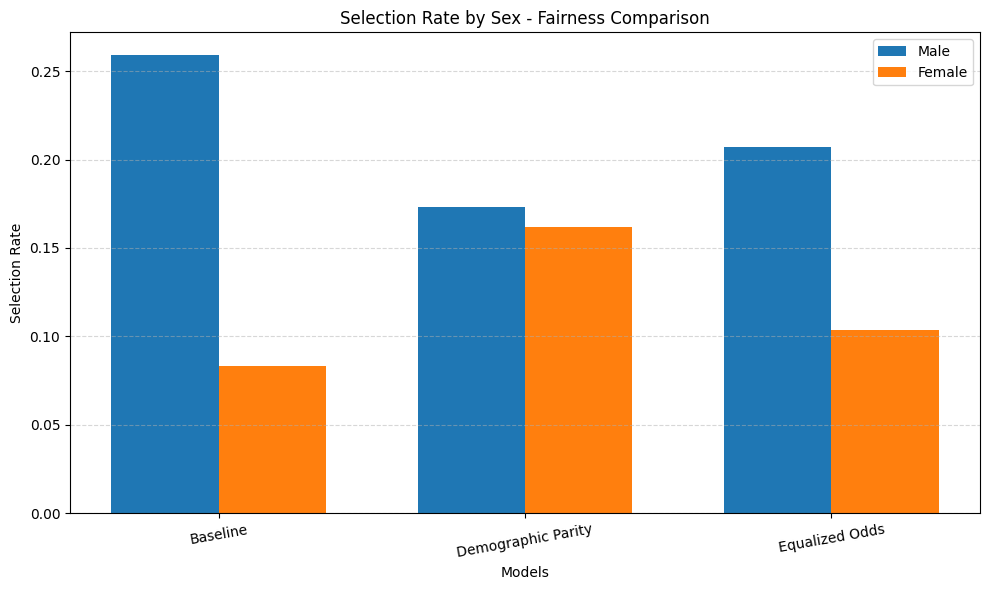

Graph saved as selection_rate_by_sex.png


In [21]:

# STEP 19: Selection Rate Comparison Graph

models = ['Baseline', 'Demographic Parity', 'Equalized Odds']

male_rates = [base_m, dp_m, eo_m]
female_rates = [base_f, dp_f, eo_f]

x = np.arange(len(models))
width = 0.35

plt.figure(figsize=(10, 6))

plt.bar(x - width/2, male_rates, width, label='Male')
plt.bar(x + width/2, female_rates, width, label='Female')

plt.xlabel('Models')
plt.ylabel('Selection Rate')
plt.title('Selection Rate by Sex - Fairness Comparison')

plt.xticks(x, models, rotation=10)
plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()

plt.savefig('selection_rate_by_sex.png', dpi=300)

plt.show()

print("Graph saved as selection_rate_by_sex.png")


In [22]:

# STEP 20: Save Final Results

comparison.to_csv('fairness_comparison.csv', index=False)

print("Comparison table saved successfully!")
print("Files generated:")
print("1. selection_rate_by_sex.png")
print("2. fairness_comparison.csv")


Comparison table saved successfully!
Files generated:
1. selection_rate_by_sex.png
2. fairness_comparison.csv


In [23]:

# STEP 21: Technical Questions and Answers

print("=" * 65)
print("TECHNICAL QUESTIONS - RESPONSIBLE AND SAFE AI")
print("=" * 65)

# Q1
print("\nQ1. BASELINE MODEL PERFORMANCE")
print("--------------------------------")
print("Overall Accuracy:", round(baseline_accuracy, 4))

print("\nGroup-wise metrics:")
display(baseline_metric_frame.by_group)

print("Disadvantaged group:",
      "Female" if base_f < base_m else "Male"
      if base_m < base_f else "Neither based on selection rate")

# Q2
print("\nQ2. BASELINE FAIRNESS AUDIT")
print("--------------------------------")
print("Demographic Parity Difference:",
      round(baseline_dp_diff, 4))
print("Demographic Parity Ratio:",
      round(baseline_dp_ratio, 4))
print("Equalized Odds Difference:",
      round(baseline_eo_diff, 4))

print("Four-Fifths Rule:",
      "PASS" if baseline_dp_ratio >= 0.80 else "FAIL")

print("The model can exhibit bias even without using sex",
      "because other features may be correlated with sex.")

# Q3
print("\nQ3. THRESHOLD OPTIMIZER COMPARISON")
print("--------------------------------")
print("Demographic Parity:")
print("DP Difference:", round(dp_diff, 4))
print("EO Difference:", round(dp_eo_diff, 4))

print("\nEqualized Odds:")
print("DP Difference:", round(eo_dp_diff, 4))
print("EO Difference:", round(eo_diff, 4))

# Q4
print("\nQ4. ACCURACY-FAIRNESS TRADE-OFF")
print("--------------------------------")
print("Baseline Accuracy:", round(baseline_accuracy, 4))
print("DP Accuracy:", round(dp_accuracy, 4))
print("EO Accuracy:", round(eo_accuracy, 4))

print("\nAccuracy change with DP:",
      round((dp_accuracy - baseline_accuracy) * 100, 2), "percentage points")

print("Accuracy change with EO:",
      round((eo_accuracy - baseline_accuracy) * 100, 2), "percentage points")

if dp_diff < eo_dp_diff:
    print("\nDP achieves better demographic parity.")
else:
    print("\nEO achieves better or equal demographic parity.")

if eo_diff < dp_eo_diff:
    print("EO achieves better equalized odds.")
else:
    print("DP achieves better or equal equalized odds.")

print("\nLimitation: Fairness mitigation may reduce predictive",
      "accuracy and requires sensitive attribute information.")


TECHNICAL QUESTIONS - RESPONSIBLE AND SAFE AI

Q1. BASELINE MODEL PERFORMANCE
--------------------------------
Overall Accuracy: 0.8524

Group-wise metrics:


,Accuracy,Selection Rate,TPR,FPR
sex,,,,
Female,0.923943,0.083220,0.531915,0.026508
Male,0.818003,0.259083,0.622465,0.092190


Disadvantaged group: Female

Q2. BASELINE FAIRNESS AUDIT
--------------------------------
Demographic Parity Difference: 0.1759
Demographic Parity Ratio: 0.3212
Equalized Odds Difference: 0.0906
Four-Fifths Rule: FAIL
The model can exhibit bias even without using sex because other features may be correlated with sex.

Q3. THRESHOLD OPTIMIZER COMPARISON
--------------------------------
Demographic Parity:
DP Difference: 0.0112
EO Difference: 0.3109

Equalized Odds:
DP Difference: 0.1037
EO Difference: 0.0379

Q4. ACCURACY-FAIRNESS TRADE-OFF
--------------------------------
Baseline Accuracy: 0.8524
DP Accuracy: 0.8322
EO Accuracy: 0.8371

Accuracy change with DP: -2.01 percentage points
Accuracy change with EO: -1.53 percentage points

DP achieves better demographic parity.
EO achieves better equalized odds.

Limitation: Fairness mitigation may reduce predictive accuracy and requires sensitive attribute information.


In [24]:

# STEP 22: Download Generated Files

from google.colab import files

files.download('selection_rate_by_sex.png')
files.download('fairness_comparison.csv')


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>